### Task

Write a **Python program** that implements both the **Explicit Method (Forward Euler)** and the **Crank–Nicolson Method** to solve the following **parabolic partial differential equation (PDE):**

$$
\begin{aligned}
\text{PDE:} \quad & \frac{\partial u}{\partial t} = \frac{\partial^2 u}{\partial x^2}, \quad -1 < x < 1, \quad t > 0,\\
\text{Initial Condition:} \quad & u(x, 0) = e^{-x^2 / (0.2)^2},\\
\text{Boundary Conditions:} \quad & u(-1, t) = 0, \\
& u(1, t) = 0.
\end{aligned}
$$

Implement both time-stepping schemes in Python.



**a)** Plot the numerical solution at several time steps (e.g., $t = 0, 0.005, 0.01, 0.015, 0.02, 0.025, 0.03$) to visualize the diffusion process and compare the behavior of the **Explicit** and **Crank–Nicolson** methods.

**b)** Perform a **convergence analysis in time and space** for $T = 0.03$:

* **Convergence:**
  Fix $k=0.5h^2$ for both methods. 
  Compute the numerical solution for successively refined spatial grids (e.g., `m = [11, 21, 41, 81, 161, 321]`). 
  Compare each result to a reference “exact” or highly resolved numerical solution (`m=641`) to compute the **spatial error**, typically using the $L_2$ or $L_\infty$ norm. 
  Estimate the **order of accuracy in space** by fitting the slope of the log–log plot of error vs. $h$.

  ---

In [87]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sparse
import scipy.sparse.linalg as linalg

# --- PDE Parameters ---
T_final = 0.03  # Final time 

# Initial condition
def initial_condition(x):
    return np.exp(-x**2 / (0.2**2))

# Boundary conditions
g_0 = lambda t: 0.0
g_1 = lambda t: 0.0

In [88]:
# --- Explicit Method ---
def solve_explicit(m, T_final):
    # 1. Create the spatial grid x from -1.0 to 1.0 with m points.
    #    Compute the spatial step size delta_x.
    x = np.linspace(-1, 1, m)
    delta_x = x[1]-x[0]
    
    # 2. Set the time step delta_t based on the stability condition (C * 0.5 * delta_x**2).
    #    Compute the number of time steps N and redefine delta_t accordingly.
    #    Create the time array t.

    # Como C no aparece en ningun sitio lo pongo como 1 y listo:
    delta_t = 0.5*delta_x**2
    
    t = np.arange(0, T_final+delta_t, delta_t) # Incluye T_final
    
    
    # 3. Initialize the solution array U with the correct shape.
    #    Apply the initial condition to the first row of U.

    n = len(t)
    U = np.zeros((n, m)) # t en filas, x en columnas
    U[0, :] = initial_condition(x)
    
    # NOTE: como la cond inicial no coincide con las de contorno en los vertices del rectangulo hay que imponerlas.
    U[0,0], U[0, -1] = g_0(t[0]), g_1(t[0])
    
    # 4. Start the time-stepping loop:
    #    - For each time step n:
    #        * Loop through the interior points of x (from 1 to m-2)
    #        * Update U[n+1, i] using the explicit finite difference formula
    #    - Apply the boundary conditions at both ends using g_0(t[n]) and g_1(t[n]).

    for j in range(n-1):
        for i in range(1, m-1):
            U[j+1, i] = U[j, i] + (delta_t/delta_x**2)*(U[j, i-1] - 2*U[j,i] + U[j, i+1])
        
            # BCs
            U[j+1,0], U[j+1, -1] = g_0(t[j+1]), g_1(t[j+1]) #NOTE: g_0 es el valor en -1
        
    # 5. Return x, t, and U as results.
    return x, t, U


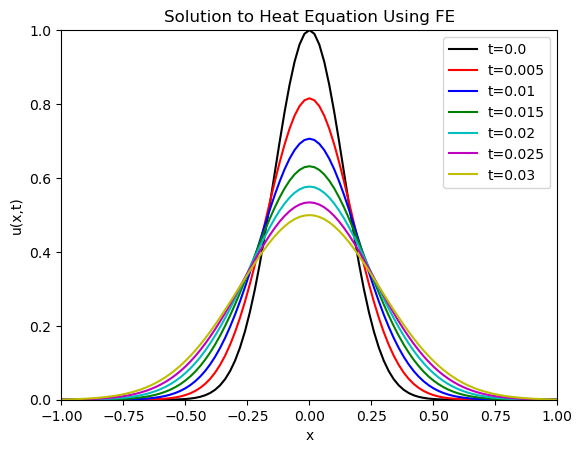

In [89]:
x, t, U = solve_explicit(m=101, T_final=T_final)

# Plot a few solutions
colors = ['k', 'r', 'b', 'g', 'c', 'm', 'y']
fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)

for (i, n) in enumerate((0, 25, 50, 75, 100, 125,150)): # Estos nº sirven porque t tiene 0.5*101**2 elementos
    axes.plot(x, U[n, :], colors[i], label='t=%s' % np.round(t[n], 4))
    axes.set_xlabel("x")
    axes.set_ylabel("u(x,t)")
    axes.set_title("Solution to Heat Equation Using FE")
    axes.set_xlim([-1,1])
    axes.set_ylim([0.0, 1.0])
axes.legend()
plt.show()

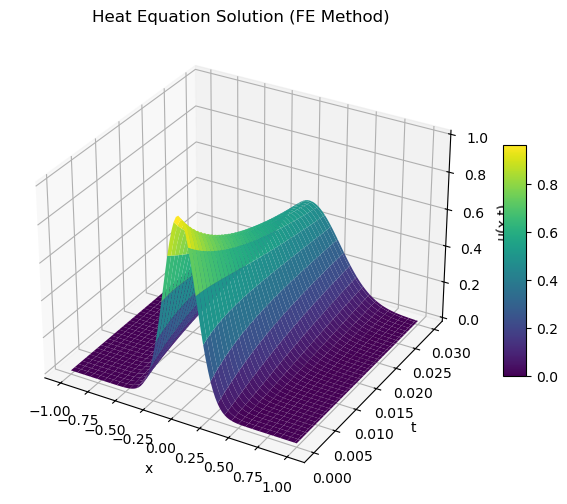

In [90]:
from matplotlib import cm

# Create meshgrid for plotting
X, T = np.meshgrid(x, t)

# Create figure and 3D axis
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
surf = ax.plot_surface(X, T, U, cmap=cm.viridis, edgecolor='none')

# Labels and title
ax.set_xlabel('x')
ax.set_ylabel('t')
ax.set_zlabel('u(x,t)')
ax.set_title('Heat Equation Solution (FE Method)')

# Optional color bar
fig.colorbar(surf, shrink=0.5, aspect=10)

plt.show()


In [91]:
# --- Crank-Nicolson Method ---
def solve_crank_nicolson(m, T_final):
    # 1. Create the spatial grid x from -1.0 to 1.0 with m points.
    #    Compute the spatial step size delta_x.
    x = np.linspace(-1, 1, m)
    delta_x = x[1]-x[0]
    
    # 2. Define the time step delta_t (e.g., proportional to delta_x for stability).
    #    Compute the total number of time steps N.
    #    Recalculate delta_t so that it fits exactly into T_final.
    #    Create the time array t from 0 to T_final.
    delta_t = delta_x/150 # Como para representar luego hay hasta 150, voy a dividir entre 150 por ejemplo.
    N = int(T_final/delta_t) # Es la parte entera por si no se puede en un numero entero de pasos
    delta_t = T_final/N # Reajustar para que se cumpla T_final = N*delta_t
    t = np.linspace(0, T_final, N)
    
    # 3. Initialize the solution array U with the correct shape.
    #    Apply the initial condition to the first row of U.
    n = len(t)
    U = np.zeros((n, m)) # t en filas, x en columnas
    U[0, :] = initial_condition(x)
    
    # NOTE: como la cond inicial no coincide con las de contorno en los vertices del rectangulo hay que imponerlas.
    U[0,0], U[0, -1] = g_0(t[0]), g_1(t[0])
    
    # --- Build matrices for INTERIOR points ---
    # 4.  Determine the number of interior points (exclude boundaries).
    #     Compute the scalar r = delta_t / (2 * delta_x**2).
    #     Create vectors and use them to build sparse matrices A and B:
    #     - A is the left-hand-side (implicit) matrix.
    #     - B is the right-hand-side (explicit) matrix.
    
    number_interiors = m-2 # Todos excepto en posiciones 0 y m-1.
    r = delta_t/(2*delta_x**2)
    
    # Creamos las diagonales para las matrices tridiagonales del método
    main_diag_A = (1+2*r)*np.ones(number_interiors) 
    sub_diag_A = (-r)*np.ones(number_interiors-1) 
    
    main_diag_B = (1-2*r)*np.ones(number_interiors) 
    sub_diag_B = r*np.ones(number_interiors-1) 
    
    A = sparse.diags(
        [sub_diag_A, main_diag_A, sub_diag_A],
        [-1, 0, 1],
        format="csc"
    )
    B = sparse.diags(
        [sub_diag_B, main_diag_B, sub_diag_B],
        [-1, 0, 1],
        format="csc"
    )
    
    # --- Time stepping loop ---
    # 5. Loop over each time step n:
    #     a. Extract interior points from U at time n.
    #     b. Compute the right-hand side b = B @ U_interior.
    #     c. Add boundary terms involving g_0(t[n]) and g_1(t[n]).
    #     d. Solve the linear system A * U_{n+1, interior} = b.
    #     e. Apply the boundary conditions at both ends for time n+1.

    for j in range(N-1):
        U_interior = U[j, 1:-1] # a.
        b = B @ U_interior # b.
        
        b[0] += r*(g_0(t[j]) + g_0(t[j+1])) # c.
        b[1] += r*(g_1(t[j]) + g_1(t[j+1])) # c.
        
        U[j+1, 1:-1] = linalg.spsolve(A, b) # d.
        U[j+1, 0], U[j+1, -1] = g_0(t[j+1]), g_1(t[j+1]) # e.
        
    # 6. Return x, t, and U as results.
    return x, t, U


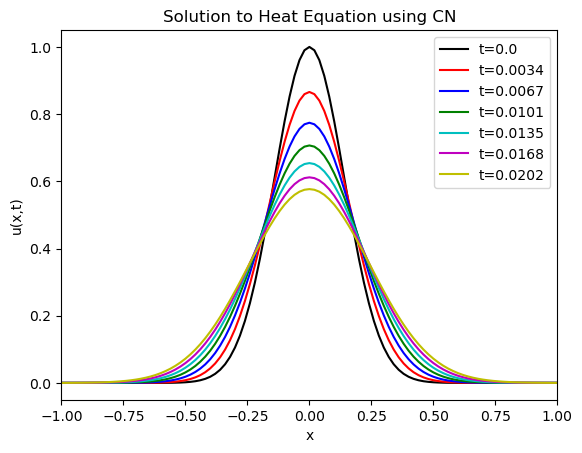

In [92]:
x, t, U = solve_crank_nicolson(m=101, T_final=T_final)


# Plot a few solutions
colors = ['k', 'r', 'b', 'g', 'c', 'm', 'y']
fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
for (i, n) in enumerate((0, 25, 50, 75, 100, 125, 150)):
    axes.plot(x, U[n, :], colors[i], label='t=%s' % np.round(t[n], 4))
    axes.set_xlabel("x")
    axes.set_ylabel("u(x,t)")
    axes.set_title("Solution to Heat Equation using CN")
    axes.set_xlim([-1,1])
axes.legend()
plt.show()

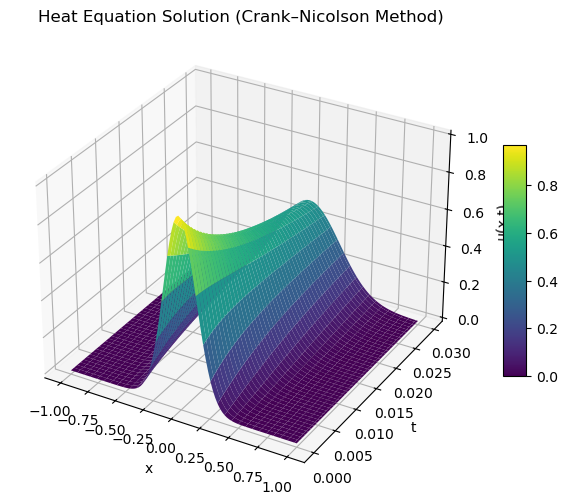

In [93]:
from matplotlib import cm

# Create meshgrid for plotting
X, T = np.meshgrid(x, t)

# Create figure and 3D axis
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
surf = ax.plot_surface(X, T, U, cmap=cm.viridis, edgecolor='none')

# Labels and title
ax.set_xlabel('x')
ax.set_ylabel('t')
ax.set_zlabel('u(x,t)')
ax.set_title('Heat Equation Solution (Crank–Nicolson Method)')

# Optional color bar
fig.colorbar(surf, shrink=0.5, aspect=10)

plt.show()


**b)** Perform a **convergence analysis in time and space** for $T = 0.03$:

* **Convergence:**
  Fix $k=0.5h^2$ for both methods. 
  Compute the numerical solution for successively refined spatial grids (e.g., `m = [11, 21, 41, 81, 161, 321]`). 
  Compare each result to a reference “exact” or highly resolved numerical solution (`m=641`) to compute the **spatial error**, typically using the $L_2$ or $L_\infty$ norm. 
  Estimate the **order of accuracy in space** by fitting the slope of the log–log plot of error vs. $h$.


In [94]:
import numpy as np # Ya estaba importado

# Calculate the fine-grid solution once
mfine = 641
x_fine, _, U_fine = solve_explicit(m=mfine, T_final=T_final)
U_fine_final = U_fine[-1, :]

# Las listas de esta forma no se usan. Voy a hacer tabla en pandas
errors_infty = []
errors_L2 = []
orders = []

ms = [11, 21, 41, 81, 161, 321]

print(f"{'m':>5} {'error infty':>15} {'error L2':>15} {'order':>10}")
print("-" * 50)


for m in ms:
    x, t, U = solve_explicit(m=m, T_final=T_final)
    
    # Step to subsample the fine solution
    step = int((mfine - 1) / (m - 1))
    
    # Compute max error at final time
    error_infty = np.max(np.abs(U[-1, :] - U_fine_final[::step])) # U_fine_final[::step] chooses element each step. Syntax: Array[start:stop:step]
    errors_infty.append(error_infty)
    
    # Compute L2 error
    error_L2 = np.sqrt(np.sum((U[-1, :] - U_fine_final[::step])**2))
    errors_L2.append(error_L2)
    
    # Compute order if not first row
    if len(errors_infty) == 1:
        order = "-"
    else:
        h1 = 1 / (ms[len(errors_infty)-2] - 1)
        h2 = 1 / (ms[len(errors_infty)-1] - 1)
        order = np.log(errors_infty[-2] / errors_infty[-1]) / np.log(h1 / h2)
        order = f"{order:.2f}"
    
    orders.append(order)
    
    print(f"{m:5d} {error_infty:15.6e} {error_L2:15.6e} {order:>10}")


    m     error infty        error L2      order
--------------------------------------------------
   11    1.134592e-01    2.006949e-01          -
   21    3.928654e-02    7.521710e-02       1.53
   41    2.939683e-03    7.976537e-03       3.74
   81    7.223410e-04    2.759026e-03       2.02
  161    6.588966e-04    3.494488e-03       0.13
  321    1.563368e-04    1.176828e-03       2.08


In [95]:
import pandas as pd

error_forward_df = pd.DataFrame(
    {
        "m":ms,
        "error infty":errors_infty,
        "error L2":errors_L2,
        "order":orders
    }
)

display(error_forward_df)

,m,error infty,error L2,order
0,11,0.113459,0.200695,-
1,21,0.039287,0.075217,1.53
2,41,0.002940,0.007977,3.74
3,81,0.000722,0.002759,2.02
4,161,0.000659,0.003494,0.13
5,321,0.000156,0.001177,2.08


In [96]:
import numpy as np

# Calculate the fine-grid solution once
mfine = 641
x_fine, _, U_fine = solve_crank_nicolson(m=mfine, T_final=T_final)
U_fine_final = U_fine[-1, :]

errors_infty = []
errors_L2 = []
orders = []

ms = [11, 21, 41, 81, 161, 321]

print(f"{'m':>5} {'error infty':>15} {'error L2':>15} {'order':>10}")
print("-" * 50)

for m in ms:
    x, t, U = solve_crank_nicolson(m=m, T_final=T_final)
    
    # Step to subsample the fine solution
    step = int((mfine - 1) / (m - 1))

    # Compute max error at final time
    error_infty = np.max(np.abs(U[-1, :] - U_fine_final[::step]))
    errors_infty.append(error_infty)
    
        
    # Compute L2 error
    error_L2 = np.sqrt(np.sum((U[-1, :] - U_fine_final[::step])**2))
    errors_L2.append(error_L2)
    
    # Compute order if not first row
    if len(errors_infty) == 1:
        order = "-"
    else:
        h1 = 1 / (ms[len(errors_infty)-2] - 1)
        h2 = 1 / (ms[len(errors_infty)-1] - 1)
        order = np.log(errors_infty[-2] / errors_infty[-1]) / np.log(h1 / h2)
        order = f"{order:.2f}"
        
    orders.append(order)
    
    print(f"{m:5d} {error_infty:15.6e} {error_L2:15.6e} {order:>10}")


    m     error infty        error L2      order
--------------------------------------------------
   11    4.130080e-02    4.889349e-02          -
   21    1.035544e-02    1.878170e-02       2.00
   41    3.477219e-03    9.073228e-03       1.57
   81    1.282799e-03    4.793076e-03       1.44
  161    4.771773e-04    2.549630e-03       1.43
  321    1.474172e-04    1.123030e-03       1.69


In [97]:
import pandas as pd

error_forward_df = pd.DataFrame(
    {
        "m":ms,
        "error infty":errors_infty,
        "error L2":errors_L2,
        "order":orders
    }
)

display(error_forward_df)

,m,error infty,error L2,order
0,11,0.041301,0.048893,-
1,21,0.010355,0.018782,2.00
2,41,0.003477,0.009073,1.57
3,81,0.001283,0.004793,1.44
4,161,0.000477,0.002550,1.43
5,321,0.000147,0.001123,1.69
